In [6]:
#importe das bibliotecas utilizadas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time


In [8]:
#Função de tratamento de imagem em matriz

def carregar_video_como_matriz(caminho_video, largura_alvo=100, altura_alvo=100):
    cap = cv2.VideoCapture(caminho_video)
    frames = []
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        # Converter para tons de cinza
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        # Redimensionar para reduzir custo computacional
        resized = cv2.resize(gray, (largura_alvo, altura_alvo))
        # Vetorizar a imagem (transformar matriz 2D em vetor 1D) e normalizar (opcional, 0 a 1)
        v = resized.flatten().astype(float) / 255.00
        frames.append(v)
        
    cap.release()
    # M terá dimensões (m x n), onde m = pixels e n = número de quadros
    M = np.column_stack(frames)
    return M, altura_alvo, largura_alvo

# Exemplo de uso:
# M, altura, largura = carregar_video_como_matriz("seu_video.mp4")

In [ ]:
carregar_video_como_matriz("data/teste2.mp4", 10, 10)

(array([[ 47.,  50.,  50., ...,  35.,  35.,  35.],
        [132., 136., 136., ..., 144., 144., 143.],
        [130., 131., 131., ..., 120., 120., 120.],
        ...,
        [128., 129., 129., ..., 118., 116., 117.],
        [ 93., 104., 100., ...,  91.,  91.,  89.],
        [141., 147., 147., ..., 115., 117., 112.]], shape=(100, 286)),
 10,
 10)

FPS: 30.0
Duração: 9.533333333333333 segundos
Quantidade de quadros: 286
Dimensão de cada quadro: (120, 160)
Dimensão da matriz M: (19200, 286)
[[ 39.  34.  29. ...  64.  64.  64.]
 [ 60.  64.  63. ...  15.  15.  15.]
 [ 26.  25.  24. ...  74.  74.  74.]
 ...
 [ 97. 105. 105. ... 133. 133. 126.]
 [131. 133. 133. ... 110. 111. 109.]
 [135. 126. 126. ... 138. 137. 136.]]


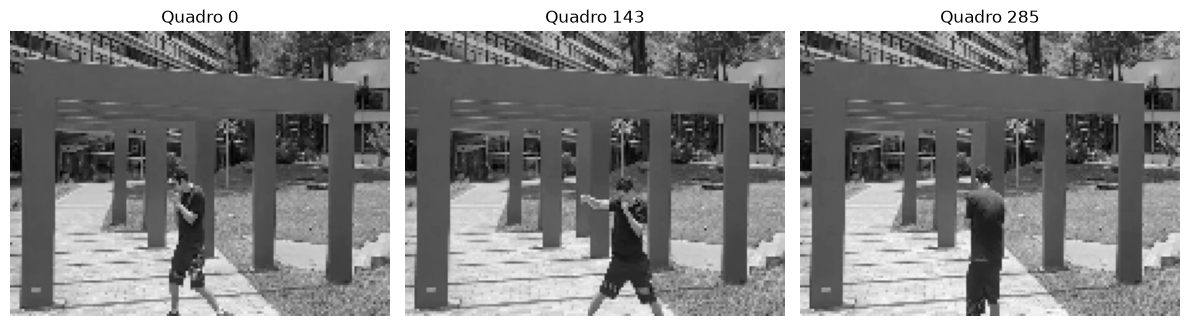

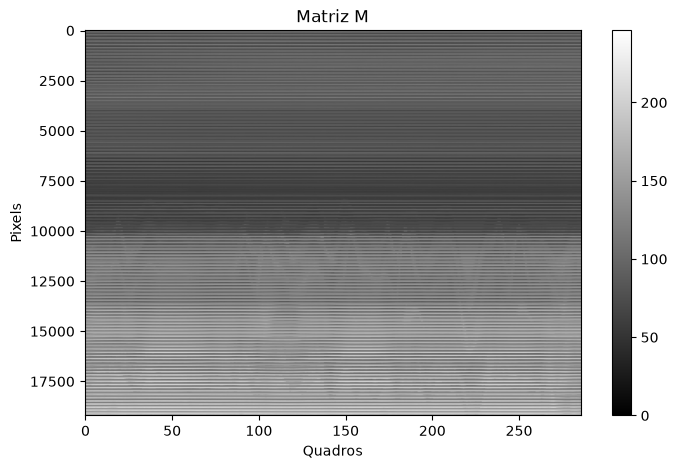

In [9]:
#Processamento de imagem usando open-cv (PRINCIPAL)

# 1. Abrir o vídeo
video = cv2.VideoCapture("data/teste2.mp4")

# Informações do vídeo
fps = video.get(cv2.CAP_PROP_FPS)
total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

duracao = total_frames / fps

print("FPS:", fps)
print("Duração:", duracao, "segundos")

# 2. Extrair e processar os quadros
frames = []

while True:
    ret, frame = video.read()

    if not ret:
        break

    # Converter para escala de cinza
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Redimensionar os quadros
    gray = cv2.resize(gray, (160, 120))

    frames.append(gray)

video.release()

# 3. Verificar os quadros
print("Quantidade de quadros:", len(frames))
print("Dimensão de cada quadro:", frames[0].shape)

# 4. Vetorizar cada quadro
vetores = [frame.flatten() for frame in frames]

# 5. Construir a matriz M
M = np.column_stack(vetores).astype(float)

print("Dimensão da matriz M:", M.shape)
print(M)

# 6. Visualizar alguns quadros
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

indices = [0, len(frames)//2, len(frames)-1]

for ax, idx in zip(axes, indices):
    ax.imshow(frames[idx], cmap='gray')
    ax.set_title(f"Quadro {idx}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# 7. Visualizar a matriz M
plt.figure(figsize=(8, 5))
plt.imshow(M, cmap='gray', aspect='auto')
plt.title("Matriz M")
plt.xlabel("Quadros")
plt.ylabel("Pixels")
plt.colorbar()
plt.show()


#Função para obter matriz M, resumindo alguns passos anteriores dentro de uma única função:


def obter_matriz_M(caminho_video, largura=160, altura=120):

    # Abrir o vídeo
    video = cv2.VideoCapture(caminho_video)

    if not video.isOpened():
        raise Exception("Não foi possível abrir o vídeo!")

    # Extrair os quadros
    frames = []

    while True:
        ret, frame = video.read()

        if not ret:
            break

        # Converter para escala de cinza
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Redimensionar os quadros
        gray = cv2.resize(gray, (largura, altura))

        frames.append(gray)

    video.release()

    # Verificar se foram extraídos quadros
    if len(frames) == 0:
        raise Exception("Nenhum quadro foi extraído!")

    # Vetorizar cada quadro
    vetores = [frame.flatten() for frame in frames]

    # Construir a matriz M
    M = np.column_stack(vetores).astype(float)

    return M



FPS: 30.0
Duração: 9.533333333333333 segundos
Quantidade de quadros: 286
Dimensão de cada quadro: (120, 160)
Dimensão da matriz M: (19200, 286)


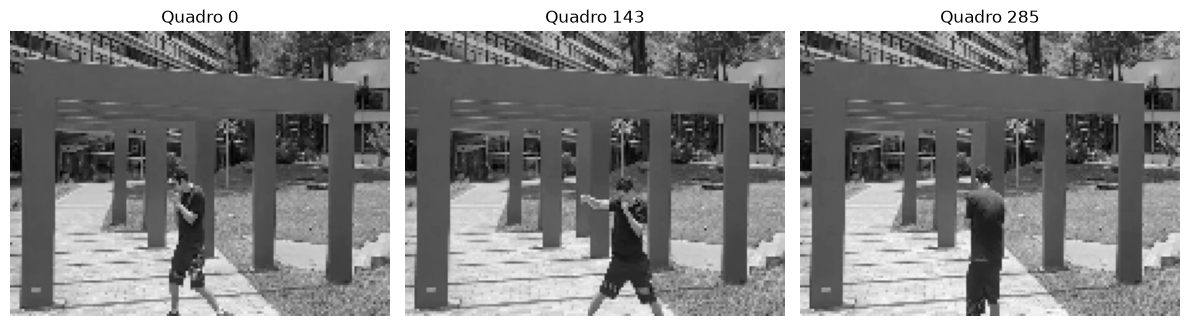

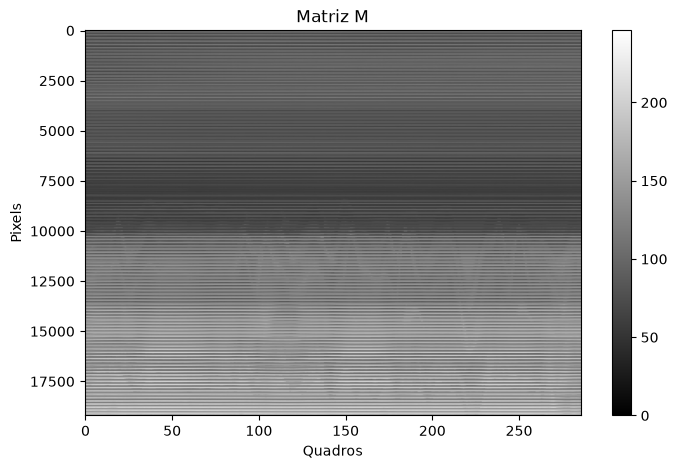

[[ 39.  34.  29. ...  64.  64.  64.]
 [ 60.  64.  63. ...  15.  15.  15.]
 [ 26.  25.  24. ...  74.  74.  74.]
 ...
 [ 97. 105. 105. ... 133. 133. 126.]
 [131. 133. 133. ... 110. 111. 109.]
 [135. 126. 126. ... 138. 137. 136.]]


In [10]:
#Teste 2

# 1. Abrir o vídeo
video = cv2.VideoCapture("data/teste2.mp4")

# Informações do vídeo
fps = video.get(cv2.CAP_PROP_FPS)
total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

duracao = total_frames / fps

print("FPS:", fps)
print("Duração:", duracao, "segundos")

# 2. Extrair e processar os quadros
frames = []

while True:
    ret, frame = video.read()

    if not ret:
        break

    # Converter para escala de cinza
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Redimensionar os quadros
    gray = cv2.resize(gray, (160, 120))

    frames.append(gray)

video.release()

# 3. Verificar os quadros
print("Quantidade de quadros:", len(frames))
print("Dimensão de cada quadro:", frames[0].shape)

# 4. Vetorizar cada quadro
vetores = [frame.flatten() for frame in frames]

# 5. Construir a matriz M
M = np.column_stack(vetores).astype(float)

print("Dimensão da matriz M:", M.shape)

# 6. Visualizar alguns quadros
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

indices = [0, len(frames)//2, len(frames)-1]

for ax, idx in zip(axes, indices):
    ax.imshow(frames[idx], cmap='gray')
    ax.set_title(f"Quadro {idx}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# 7. Visualizar a matriz M
plt.figure(figsize=(8, 5))
plt.imshow(M, cmap='gray', aspect='auto')
plt.title("Matriz M")
plt.xlabel("Quadros")
plt.ylabel("Pixels")
plt.colorbar()
plt.show()

print(M)


In [11]:
#Funções de decomposição SVD

#Definicao da matriz devidamente formatada
def Matriz(A):
    M = A@(np.transpose(A))
    return M

#Decompoe as matrizes Q e R
def Matrizes_Q_R(M):
    Q, R = np.linalg.qr(M)
    return Q, R

#Calculo dos valores singulares
def Singulares_QR(B):

   B = np.array(B)
   tol = 1e-15
   W = B.copy()

   for k in range(1000):
      Qk, Rk = Matrizes_Q_R(W)
      Wr = W.copy()
      W = Rk @ Qk
      er = np.linalg.norm(np.diag(W) - np.diag(Wr)) / np.linalg.norm(np.diag(W)) 
      er = np.abs(er)

      if er < tol:
         break

   autoval = []
   for j in range(W.shape[0]):
      autoval.append(np.max(np.sqrt(W[j][j].real),0))

   autoval.sort(reverse= True)
   autoval = np.array(autoval)
   return autoval

         
def Autovetores_Direita(A, autv):
   tol=1e-15
   iter= 1000
   A = np.array(A)
   n= A.shape[0]
   I = np.eye(n)
   autovetores = []

   e = 1e-15

   
   for k in range(n):
      qold = np.random.rand(n)
      mu = autv[k] + e
      B= (A - mu*I)

      norm = 1                                       
      cont = 0                                       
      while norm > tol and cont < iter:              
         qnew = np.linalg.solve(B,qold)              
         qnew = qnew/np.linalg.norm(qnew,ord=2)      
         norm = 1 - np.abs(np.vdot(qold, qnew))      
         qold = qnew                                 
         cont += 1

         autovetores.append(qold)     

   
   autovetores = np.array(autovetores)

   return autovetores

def Autovetores_esquerda(A, autovec, autoval):
   u = []
   n = len(autoval)
   for i in range(n):
      u.append((A @ autovec[i])/autoval[i])

   u = np.array(u)
   return u

def Matrizes(A, AutovecL, AutovecR, Autoval):
   n = A.shape[0]

   U = []
   S = np.eye(n)
   V = []

   for j in range(n):
        U.append(AutovecL[j])
        S[j][j] = Autoval[j]
        V.append(AutovecR[j])

   U = np.array(U)
   V = np.array(V).T

   return U, S, V

def DecompsicaoSVD(A):
   inicio = time.perf_counter()
   M = Matriz(A)
   ValoresSingulares = Singulares_QR(M)
   VecR = Autovetores_Direita(M, ValoresSingulares)
   VecL = Autovetores_esquerda(M,VecR, ValoresSingulares)
   U, S, V = Matrizes(M, VecL, VecR, ValoresSingulares)
   fim = time.perf_counter()
   tempo = fim - inicio
   return U, S, V, tempo

In [ ]:
# Comparacao com o svd nativo:

A = np.array([[1,2,3],[9,0,7],[2,5,0]])

u,s,v,t = DecompsicaoSVD(A)
print(f"Minha solução eh: U: {u}\n S: {s}\n V: {v}")
print("")
print("O tempo de execucao foi de:", t)
print("")

iniProg = time.perf_counter()
m, n, p = np.linalg.svd(A)
fimProg = time.perf_counter()
tempoProg= fimProg - iniProg

print(f"A solucao do programa foi: U: {m}\n S: {n}\n V: {p}")
print("")
print("O tempo de execucao do programa foi:", tempoProg)
print("")
print(f"A diferenca foi: U: {u - m}\n S: {s - (n @ np.eye(3))}\n Vt: {v - p}")

Minha solução eh: U: [[ 1.04150915  2.85946252  2.17684554]
 [ 1.45305745 -0.12093696  2.05989808]
 [-0.94892687 -0.33088894  3.60804338]]
 S: [[11.87441822  0.          0.        ]
 [ 0.          5.274628    0.        ]
 [ 0.          0.          2.04364658]]
 V: [[-0.36341519  0.96105908 -0.83993636]
 [ 0.21969668 -0.24451689  0.11520134]
 [ 0.90535229  0.12875142  0.53031647]]

O tempo de execucao foi de: 0.38098390004597604

A solucao do programa foi: U: [[-0.24217417 -0.27582641  0.93019969]
 [-0.95354174  0.24473231 -0.17568222]
 [-0.17919212 -0.92952993 -0.32227984]]
 S: [11.87441822  5.274628    2.04364658]
 V: [[-0.77329549 -0.11624224 -0.62329914]
 [ 0.01283588 -0.98571927  0.16790699]
 [-0.63391586  0.12184113  0.76374434]]

O tempo de execucao do programa foi: 0.002310000010766089

A diferenca foi: U: [[ 1.28368332  3.13528892  1.24664585]
 [ 2.4065992  -0.36566926  2.23558031]
 [-0.76973475  0.59864099  3.93032322]]
 S: [[-8.88178420e-15 -5.27462800e+00 -2.04364658e+00]
 [

In [ ]:
# Parte 3 APROXIMAÇÃO DE BAIXO POSTO 
def aproximacao_baixo_posto(U, S, Vt, k):
    # Calcula a aproximação de posto no máximo k (Eq. 11):
    # Garante que os valores singulares estejam em um vetor 1D
    s = np.diag(S) if S.ndim == 2 else S
    r = len(s)

    if not (1 <= k <= r):
        raise ValueError(f"k deve estar entre 1 e {r}.")

    # Mantém apenas os k maiores valores singulares e seus vetores correspondentes
    U_k = U[:, :k]
    Sigma_k = np.diag(s[:k])
    Vt_k = Vt[:k, :]

    L_k = U_k @ Sigma_k @ Vt_k
    return L_k


def avaliar_aproximacao(M, L_k, s=None, k=None):
    """
    Calcula o erro na norma de Frobenius ||M - L_k||_F (Eq. 12)
    e o erro relativo percentual.
    """
    erro_frob = np.linalg.norm(M - L_k, ord='fro')
    norma_M = np.linalg.norm(M, ord='fro')
    erro_relativo = erro_frob / norma_M

    resultado = {
        "erro_frobenius": erro_frob,
        "erro_relativo": erro_relativo,
    }

    # Verificação teórica: ||M - L_k||_F = sqrt(sum_{i=k+1}^r sigma_i^2)
    if s is not None and k is not None:
        s_vec = np.diag(s) if s.ndim == 2 else s
        resultado["erro_teorico_sigmas"] = np.sqrt(np.sum(s_vec[k:] ** 2))

    return resultado

# 1. Obter a matriz M do vídeo
largura, altura = 160, 120
M = obter_matriz_M("data/teste2.mp4", largura=largura, altura=altura)

# 2. Calcular a SVD reduzida de M (M = U @ diag(s) @ Vt)
U, s, Vt = np.linalg.svd(M, full_matrices=False)
r = len(s)
print(f"Dimensão de M: {M.shape} | Posto máximo r: {r}")

# 3. Testar diferentes valores de posto k <= r (arbitrários)
valores_k = [1, 2, 3, 4, 5, 10, 20, 100]
valores_k = [k for k in valores_k if k <= r]

aproximacoes = {}
for k in valores_k:
    L_k = aproximacao_baixo_posto(U, s, Vt, k)
    metricas = avaliar_aproximacao(M, L_k, s=s, k=k)
    aproximacoes[k] = L_k

    print(
        f"k = {k:2d} | "
        f"||M - L_k||_F = {metricas['erro_frobenius']:.4f} | "
        f"Teórico = {metricas['erro_teorico_sigmas']:.4f} | "
        f"Erro relativo = {metricas['erro_relativo']*100:.2f}%"
    )

Dimensão de M: (19200, 286) | Posto máximo r: 286
k =  1 | ||M - L_k||_F = 39408.2242 | Teórico = 39408.2242 | Erro relativo = 14.12%
k =  2 | ||M - L_k||_F = 34116.2918 | Teórico = 34116.2918 | Erro relativo = 12.22%
k =  3 | ||M - L_k||_F = 29667.3261 | Teórico = 29667.3261 | Erro relativo = 10.63%
k =  4 | ||M - L_k||_F = 27629.4695 | Teórico = 27629.4695 | Erro relativo = 9.90%
k =  5 | ||M - L_k||_F = 26298.0019 | Teórico = 26298.0019 | Erro relativo = 9.42%
k = 10 | ||M - L_k||_F = 22448.2125 | Teórico = 22448.2125 | Erro relativo = 8.04%
k = 20 | ||M - L_k||_F = 18788.7216 | Teórico = 18788.7216 | Erro relativo = 6.73%
k = 100 | ||M - L_k||_F = 9917.9439 | Teórico = 9917.9439 | Erro relativo = 3.55%


[1, 2, 3, 4, 5, 10, 20, 100]


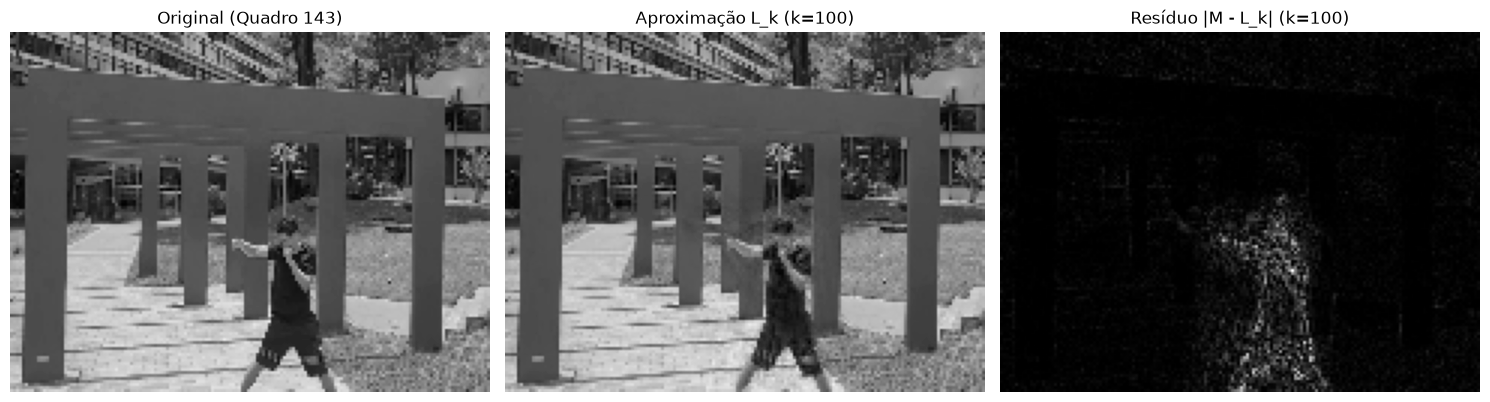

In [ ]:
print(valores_k)

# Visualização dos quadros reconstruídos (Lk e do resíduo (M - Lk))
idx_quadro = M.shape[1] // 2  # Quadro central do vídeo (PRA TESTE)
k_escolhido = valores_k[0]    # Defina o k que deseja de 0 a 7 (1, 2, 3, 4, 5, 10, 20, 100)
L_k = aproximacoes[k_escolhido] # influencia no quão bom é o recorte 

quadro_original = M[:, idx_quadro].reshape((altura, largura))
quadro_Lk = np.clip(L_k[:, idx_quadro].reshape((altura, largura)), 0, 255)
quadro_residuo = np.abs(M[:, idx_quadro] - L_k[:, idx_quadro]).reshape((altura, largura))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(quadro_original, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f"Original (Quadro {idx_quadro})")
axes[0].axis('off')

axes[1].imshow(quadro_Lk, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Aproximação L_k (k={k_escolhido})")
axes[1].axis('off')

axes[2].imshow(quadro_residuo, cmap='gray')
axes[2].set_title(f"Resíduo |M - L_k| (k={k_escolhido})")
axes[2].axis('off')

plt.tight_layout()
plt.show()